<center><h1>Vo_Kevin_HW7</h1></center>

Name: Kevin Vo
<br>
Github Username: kb-vo
<br>
USC ID: 5124764281

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [42]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.exceptions import ConvergenceWarning
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

### (a) Download the Anuran Calls (MFCCs) Data Set

In [43]:
df = pd.read_csv('../data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv')
X = df.drop(columns=['Family', 'Genus', 'Species', 'RecordID'])
y = df[['Family', 'Genus', 'Species']]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

### (b) Train a classifier for each label

#### (i) Research

Exact match: the fraction of instances where all labels are predicted correctly $$\frac{1}{n}\sum_{i=1}^{n} I(y_{i} = \hat{y}_{i})$$

Hamming loss: the fraction of individual labels predicted incorrectly, across all instances and labels $$\frac{1}{nL}\sum_{i=1}^{n}\sum_{j=1}^{L} I(y_{ij} \neq \hat{y}_{ij})$$

Hamming score: the fraction of individual labels predicted correctly, equal to 1 - Hamming loss

#### (ii) Train a SVM for each of the labels

In [44]:
param_grid = {
    'estimator__C': np.logspace(-3, 6, 10),
    'estimator__gamma': np.linspace(0.1, 2, 20),
}
y_pred = pd.DataFrame(index=y_test.index)
for label in y_train.columns:
    grid = GridSearchCV(OneVsRestClassifier(SVC()), param_grid, cv=10, n_jobs=-1)
    grid.fit(X_train, y_train[label])
    y_pred[label] = grid.predict(X_test)

exact_match = (y_pred == y_test).all(axis=1).mean()
hamming_loss = (y_pred != y_test).to_numpy().mean()
print('Exact match:', exact_match)
print('Hamming loss:', hamming_loss)
print('Hamming score:', 1 - hamming_loss)

Exact match: 0.9893469198703103
Hamming loss: 0.007565230816736143
Hamming score: 0.9924347691832639


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [45]:
warnings.filterwarnings('ignore', category=ConvergenceWarning)

param_grid = {'linearsvc__C': np.logspace(-3, 6, 10)}
y_pred = pd.DataFrame(index=y_test.index)
for label in y_train.columns:
    grid = GridSearchCV(make_pipeline(StandardScaler(), LinearSVC(penalty='l1')), param_grid, cv=10, n_jobs=-1)
    grid.fit(X_train, y_train[label])
    y_pred[label] = grid.predict(X_test)

exact_match = (y_pred == y_test).all(axis=1).mean()
hamming_loss = (y_pred != y_test).to_numpy().mean()
print('Exact match:', exact_match)
print('Hamming loss:', hamming_loss)
print('Hamming score:', 1 - hamming_loss)

Exact match: 0.9129226493747105
Hamming loss: 0.05681642735834491
Hamming score: 0.9431835726416551


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [46]:
param_grid = {'linearsvc__C': np.logspace(-3, 6, 10)}
y_pred = pd.DataFrame(index=y_test.index)
for label in y_train.columns:
    grid = GridSearchCV(make_imb_pipeline(StandardScaler(), SMOTE(random_state=42), LinearSVC(penalty='l1')), param_grid, cv=10, n_jobs=-1)
    grid.fit(X_train, y_train[label])
    y_pred[label] = grid.predict(X_test)

exact_match = (y_pred == y_test).all(axis=1).mean()
hamming_loss = (y_pred != y_test).to_numpy().mean()
print('Exact match:', exact_match)
print('Hamming loss:', hamming_loss)
print('Hamming score:', 1 - hamming_loss)

Exact match: 0.8522464103751737
Hamming loss: 0.07735062528948587
Hamming score: 0.9226493747105141


The Gaussian kernel SVM performed best, which suggests the classes are not linearly separable. The L1-penalized linear SVM was worse, since it is limited to linear boundaries. Adding SMOTE lowered the scores further, likely because oversampling the minority classes costs accuracy on the majority classes that make up most of the test set.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [47]:
best_ks = []
cluster_labels = []
for i in range(50):
    scores = {}
    for k in range(2, 51):
        labels = KMeans(n_clusters=k, random_state=i).fit_predict(X)
        scores[k] = silhouette_score(X, labels)
    best_k = max(scores, key=scores.get)
    best_ks.append(best_k)
    cluster_labels.append(KMeans(n_clusters=best_k, random_state=i).fit_predict(X))

### (b) Determine which family is the majority

In [48]:
majority_labels = [y.groupby(labels).agg(lambda s: s.mode()[0]) for labels in cluster_labels]

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [49]:
hamming_distances = []
for labels, majority in zip(cluster_labels, majority_labels):
    wrong = majority.loc[labels].to_numpy() != y.to_numpy()
    hamming_distances.append(wrong.sum(axis=1).mean())

hamming_distances = np.array(hamming_distances)
hamming_losses = hamming_distances / 3
hamming_scores = 1 - hamming_losses
print(f'Hamming distance: mean {hamming_distances.mean()}, std {hamming_distances.std()}')
print(f'Hamming loss: mean {hamming_losses.mean()}, std {hamming_losses.std()}')
print(f'Hamming score: mean {hamming_scores.mean()}, std {hamming_scores.std()}')

Hamming distance: mean 0.7186685198054203, std 0.12959433572039117
Hamming loss: mean 0.23955617326847353, std 0.04319811190679705
Hamming score: mean 0.7604438267315266, std 0.04319811190679705


## 3. ISLR 12.6.2

### (a)

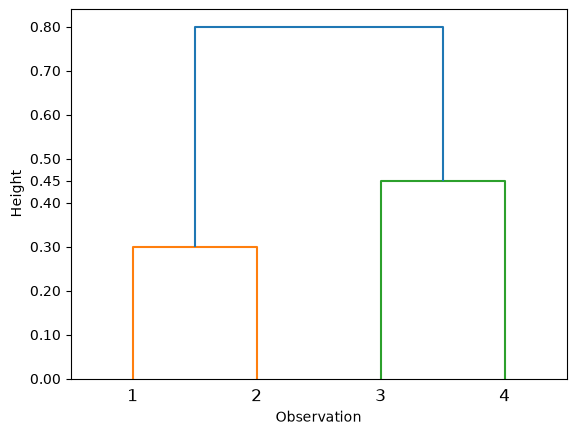

In [50]:
D = np.array([
    [0, 0.3, 0.4, 0.7],
    [0.3, 0, 0.5, 0.8],
    [0.4, 0.5, 0, 0.45],
    [0.7, 0.8, 0.45, 0],
])

dendrogram(linkage(squareform(D), method='complete'), labels=[1, 2, 3, 4])
plt.xlabel('Observation')
plt.ylabel('Height')
plt.yticks(np.append(np.arange(0, 0.9, 0.1), 0.45)) 
plt.show()

### (b)

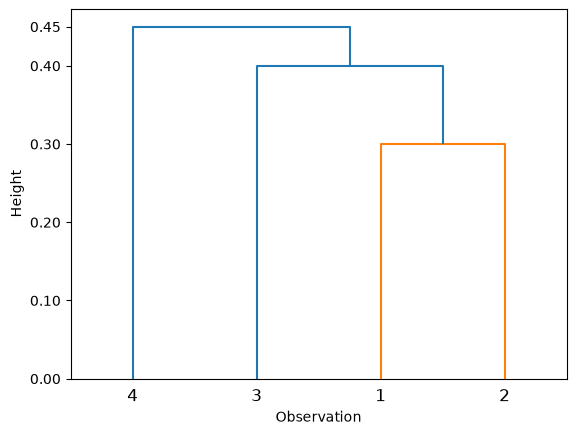

In [51]:
dendrogram(linkage(squareform(D), method='single'), labels=[1, 2, 3, 4])
plt.xlabel('Observation')
plt.ylabel('Height')
plt.yticks(np.append(np.arange(0, 0.5, 0.1), 0.45))
plt.show()

### (c)

Observations 1 and 2 are in one cluster and observations 3 and 4 are in the other one.

### (d)

Observations 1, 2, and 3 are in one cluster and observation 4 is in the other one.

### (e)

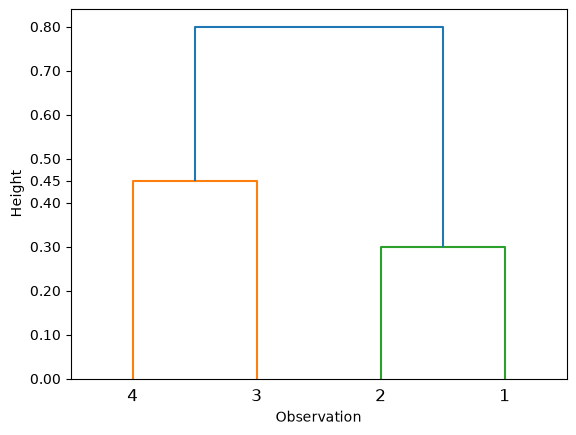

In [52]:
dendrogram(linkage(squareform(D), method='complete'), labels=[1, 2, 3, 4], distance_sort='descending')
plt.xlabel('Observation')
plt.ylabel('Height')
plt.yticks(np.append(np.arange(0, 0.9, 0.1), 0.45)) 
plt.show()